# Exercise 2: Entmagnetisierungsfeld per FFT

Das Streufeld einer Magnetisierung ist eine Faltung, $\vec h(\vec r) = \int K(\vec r - \vec r\,')\,\vec m(\vec r\,')\,d\vec r\,'$.
Direkt kostet sie auf $N$ Zellen $O(N^2)$, mit dem Faltungssatz $O(N\log N)$. Zellen haben die Größe 1.

Die Funktionen stehen in `demag.py`, die Tests in `test_demag.py` (`python -m pytest -v`). Sie wurden zuerst geschrieben:
jede FFT-Variante muss die direkte Summe bis auf Rundung reproduzieren, die direkte Summe ist an Handfällen geprüft.
Hintergrund in `THEORIE.md`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from demag import (charge_field_3d, demag_direct_1d, demag_direct_3d, demag_fft_1d,
                   demag_fft_1d_fast, demag_fft_3d, dipole_field, kernel_1d)

plt.rcParams["figure.dpi"] = 110


def best_time(f, *args, repeat=5):
    """Shortest of several runs, in seconds."""
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        f(*args)
        times.append(time.perf_counter() - t0)
    return min(times)

## 1 Entmagnetisierungsfeld in 1D

### 1a) Feld eines Punktdipols und 1D-Kernel

$$\vec h(\vec r) = \frac{1}{4\pi r^3}\big(3(\vec m\cdot\hat r)\,\hat r - \vec m\big)$$

Auf der x-Achse ist $\hat r = \pm\hat x$. Für $\vec m = m_x\hat x$ ist $(\vec m\cdot\hat r)\hat r = m_x\hat x$, also

$$h_x = \frac{3-1}{4\pi |x|^3}\,m_x = \underbrace{\frac{1}{2\pi |x|^3}}_{K_{xx}(x)}\,m_x .$$

Der Kernel ist gerade in $x$ und positiv: auf der Achse zeigt das Feld in Richtung von $\vec m$.

K_xx(0) = -0.3333,  K_xx(1) = 0.1592


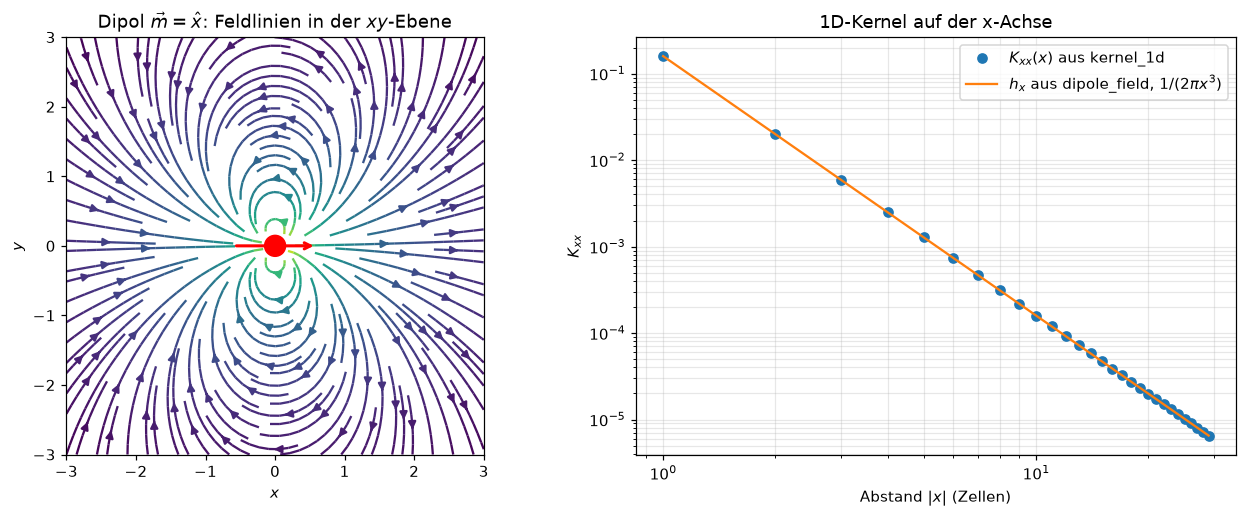

In [2]:
m0 = np.array([1.0, 0.0, 0.0])
g = np.linspace(-3, 3, 41)
X, Y = np.meshgrid(g, g, indexing="xy")
r = np.stack([X, Y, 0 * X], axis=-1)
with np.errstate(invalid="ignore", divide="ignore"):
    h = dipole_field(m0, r)
hn = np.linalg.norm(h, axis=-1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ax1.streamplot(X, Y, h[..., 0], h[..., 1], color=np.log10(hn), cmap="viridis", density=1.4)
ax1.add_patch(plt.Circle((0, 0), 0.15, color="red"))
ax1.annotate("", xy=(0.6, 0), xytext=(-0.6, 0), arrowprops=dict(arrowstyle="->", color="red", lw=2))
ax1.set(xlabel="$x$", ylabel="$y$", title=r"Dipol $\vec m=\hat x$: Feldlinien in der $xy$-Ebene", aspect="equal")

x = np.arange(1, 30)
ax2.loglog(x, kernel_1d(x), "o", label=r"$K_{xx}(x)$ aus kernel_1d")
ax2.loglog(x, dipole_field(m0, np.stack([x, 0 * x, 0 * x], axis=-1).astype(float))[:, 0], "-",
           label=r"$h_x$ aus dipole_field, $1/(2\pi x^3)$")
ax2.set(xlabel="Abstand $|x|$ (Zellen)", ylabel=r"$K_{xx}$", title="1D-Kernel auf der x-Achse")
ax2.legend(); ax2.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print(f"K_xx(0) = {kernel_1d(np.array([0]))[0]:.4f},  K_xx(1) = {kernel_1d(np.array([1]))[0]:.4f}")

> **Frage:** Wie wird die Selbstwechselwirkung ($x = 0$) behandelt?
>
> **Antwort:** Das Punktdipolfeld divergiert bei $r = 0$ wie $1/r^3$, dort ist es nicht definiert.
> Physikalisch ist jede Zelle ein homogen magnetisierter Würfel. Sein mittleres Eigenfeld ist $-N\vec m$ mit dem
> Entmagnetisierungsfaktor $N = 1/3$ (Würfel, aus Symmetrie $N_x = N_y = N_z$ und $N_x+N_y+N_z = 1$).
> Deshalb setze ich $K(0) = -\tfrac13 I$, also $K_{xx}(0) = -1/3$.
> Das ist genau der Delta-Anteil, der in der Distribution $\partial_i\partial_j \frac{1}{4\pi r}$ steckt (siehe 2d und `THEORIE.md`).
> $K(0) = 0$ (Selbstterm einfach weglassen) wäre die andere übliche Wahl; dann fehlt im Inneren eines Körpers genau $-\vec m/3$.

### 1b) Direkte Summation

$h_i = \sum_j K_{xx}(i-j)\, m_j$. Testfall: $N = 64$ Zellen, $m_x = 1$ auf den Zellen $16 \dots 47$ (32 Zellen).

Mitte  (i=31): h = +0.0487   unendliche Kette: -1/3 + zeta(3)/pi    = +0.0493
Rand   (i=16): h = -0.1421   halbunendliche Kette: -1/3 + zeta(3)/2pi = -0.1420
außen  (i=15): h = +0.1912   (Streufeld, zeigt in +x)
außen  (i= 0): h = +2.96e-04


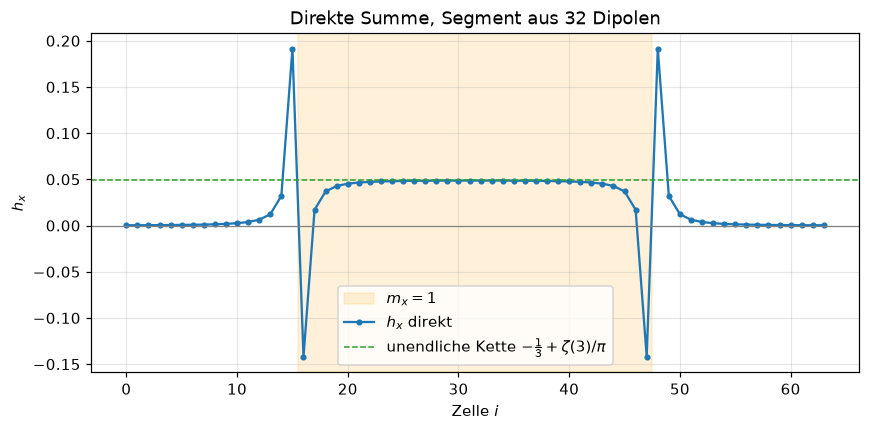

In [3]:
N = 64
m_seg = np.zeros(N)
m_seg[16:48] = 1.0
h_seg = demag_direct_1d(m_seg)

fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(15.5, 47.5, color="orange", alpha=0.15, label="$m_x = 1$")
ax.plot(np.arange(N), h_seg, "o-", markersize=3, label="$h_x$ direkt")
ax.axhline(0, color="gray", lw=0.8)
ax.axhline(-1 / 3 + 1.2020569 / np.pi, color="C2", ls="--", lw=1, label=r"unendliche Kette $-\frac{1}{3}+\zeta(3)/\pi$")
ax.set(xlabel="Zelle $i$", ylabel="$h_x$", title="Direkte Summe, Segment aus 32 Dipolen")
ax.legend(); ax.grid(True, alpha=0.3); plt.show()

zeta3 = 1.2020569031595942
print(f"Mitte  (i=31): h = {h_seg[31]:+.4f}   unendliche Kette: -1/3 + zeta(3)/pi    = {-1/3 + zeta3/np.pi:+.4f}")
print(f"Rand   (i=16): h = {h_seg[16]:+.4f}   halbunendliche Kette: -1/3 + zeta(3)/2pi = {-1/3 + zeta3/(2*np.pi):+.4f}")
print(f"außen  (i=15): h = {h_seg[15]:+.4f}   (Streufeld, zeigt in +x)")
print(f"außen  (i= 0): h = {h_seg[0]:+.2e}")

#### Beobachtungen

- **Mitte:** $h_x = +0.0487$, fast genau der Wert der unendlichen Kette $-\tfrac13 + 2\sum_{n\ge1}\frac{1}{2\pi n^3} = -\tfrac13 + \zeta(3)/\pi = +0.0493$.
  Die Nachbarn liegen auf der Achse, ihr Feld zeigt in Richtung $\vec m$ und hebt den Selbstterm $-1/3$ fast auf.
- **Ende des Segments:** $h_x = -0.142$, wie die halbunendliche Kette ($-\tfrac13 + \zeta(3)/2\pi = -0.142$). Am Rand fehlen die Nachbarn auf einer Seite,
  das Feld ist entmagnetisierend (gegen $\vec m$). Hier sitzen die magnetischen Ladungen $\rho = -\partial_x m_x$.
- **Außerhalb:** direkt neben dem Ende $+0.19$, das Streufeld zeigt in $+x$ und fällt wie $1/x^2$ ab (Feld der Endladungen).
- Die Abweichung vom Grenzwert ist auf wenige Zellen am Rand beschränkt, weil der Kernel wie $1/x^3$ abfällt.
- Physikalisch hätte ein langer, dünner Stab in der Mitte $h \approx 0$ ($N \to 0$). Der kleine positive Wert ist ein Fehler der
  Punktdipol-Näherung zwischen direkten Nachbarn; ein exakter Würfel-Würfel-Kernel (Newell) würde ihn beseitigen.

### 1c) Faltungssatz: lineare statt zyklischer Faltung

Die DFT faltet zyklisch: $\mathcal F^{-1}(\hat K\hat m)_i = \sum_j K_{(i-j) \bmod L}\, m_j$. Ohne Padding ($L = N$) wird der Index
$i - j < 0$ auf $i - j + N$ gefaltet. Dann wirken die Dipole am linken Rand auf das rechte Ende, als wäre die Kette ein Ring.

Abhilfe: $m$ mit Nullen auf $L \ge 2N-1$ auffüllen. Alle Abstände $i - j \in [-(N-1), N-1]$ kommen dann vor, ohne dass
zwei davon auf denselben Index modulo $L$ fallen. Der Kernel muss dazu in **Wraparound-Anordnung** liegen:
Index $0, 1, \dots, N-1$ für die Abstände $0, 1, \dots, N-1$, die negativen Abstände $-(N-1), \dots, -1$ am Ende des Arrays.
Das ist genau die Reihenfolge von `np.fft.fftfreq(L, 1/L)`.

max |FFT gepaddet - direkt|  = 2.0e-16
max |FFT zyklisch - direkt|  = 1.7e-04
Dipol bei i=0, Feld bei i=N-1: linear 6.37e-07, zyklisch 1.59e-01 (= K(1) = 1.59e-01)


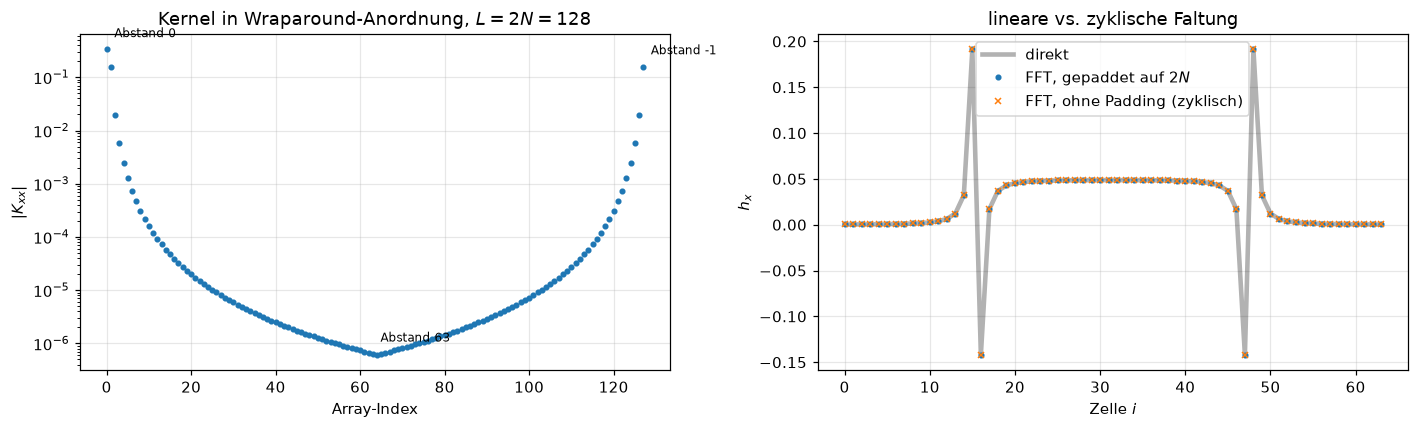

In [4]:
# cyclic convolution without padding, kernel on a ring of length N
d_ring = np.fft.fftfreq(N, 1 / N)
h_cyclic = np.fft.ifft(np.fft.fft(kernel_1d(d_ring)) * np.fft.fft(m_seg)).real
h_linear = demag_fft_1d(m_seg)

L = 2 * N
d = np.fft.fftfreq(L, 1 / L).astype(int)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.semilogy(np.arange(L), np.abs(kernel_1d(d)), "o", markersize=3)
ax1.set(xlabel="Array-Index", ylabel=r"$|K_{xx}|$", title=f"Kernel in Wraparound-Anordnung, $L = 2N = {L}$")
for k in (0, N - 1, L - 1):
    ax1.annotate(f"Abstand {d[k]}", (k, abs(kernel_1d(d[k:k+1]))[0]), textcoords="offset points", xytext=(5, 8), fontsize=8)
ax1.grid(True, alpha=0.3)
ax2.plot(h_seg, "k-", lw=3, alpha=0.3, label="direkt")
ax2.plot(h_linear, "o", markersize=3, label="FFT, gepaddet auf $2N$")
ax2.plot(h_cyclic, "x", markersize=4, label="FFT, ohne Padding (zyklisch)")
ax2.set(xlabel="Zelle $i$", ylabel="$h_x$", title="lineare vs. zyklische Faltung")
ax2.legend(); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print(f"max |FFT gepaddet - direkt|  = {np.max(np.abs(h_linear - h_seg)):.1e}")
print(f"max |FFT zyklisch - direkt|  = {np.max(np.abs(h_cyclic - h_seg)):.1e}")
m_end = np.zeros(N); m_end[0] = 1
print(f"Dipol bei i=0, Feld bei i=N-1: linear {demag_fft_1d(m_end)[-1]:.2e}, zyklisch "
      f"{np.fft.ifft(np.fft.fft(kernel_1d(d_ring)) * np.fft.fft(m_end)).real[-1]:.2e} (= K(1) = {1/(2*np.pi):.2e})")

#### Beobachtungen

- Gepaddete FFT und direkte Summe stimmen bis auf $2\cdot10^{-16}$ überein: das ist dieselbe Summe, nur anders gerechnet.
- Die zyklische Faltung ohne Padding weicht hier nur um $1.7\cdot10^{-4}$ ab, weil links und rechts vom Segment je 16 Nullen liegen
  und der Kernel bei Abstand 17 schon klein ist. Ein Dipol direkt am Rand zeigt den Fehler deutlich: Am anderen Ende
  liefert die zyklische Faltung $0.159 = K(1)$, das Feld eines **direkten Nachbarn**, statt richtig $6.4\cdot10^{-7} = K(63)$.
- **Warum $L \ge 2N - 1$?** Es gibt $2N - 1$ verschiedene Abstände $-(N-1)\dots N-1$. Erst bei dieser Länge bekommt jeder einen
  eigenen Index modulo $L$. Mit $L = 2N$ bleibt ein Index (Abstand $\pm N$) übrig; er trifft nur Nullen von $m$ und ist egal.

### 1d) Laufzeit direkt vs. FFT

Gemessen wird jeweils die schnellste von mehreren Wiederholungen mit zufälligem $m$.
Die direkte Summe ist eine Python-Schleife über $i$, vektorisiert über $j$; zusätzlich zum Vergleich `np.convolve`
(ebenfalls direkte Summation, aber in C).

Steigung direkt (Schleife) 1.72, np.convolve 1.85; FFT: 5.80 ns * N log2 N
N =    16: direkt     0.080 ms, FFT   0.017 ms, Faktor      4.6
N =    32: direkt     0.158 ms, FFT   0.017 ms, Faktor      9.2
N =    64: direkt     0.334 ms, FFT   0.019 ms, Faktor     17.4
N =   128: direkt     0.769 ms, FFT   0.023 ms, Faktor     33.7
N =   256: direkt     1.845 ms, FFT   0.030 ms, Faktor     60.8
N =   512: direkt     5.008 ms, FFT   0.057 ms, Faktor     88.1
N =  1024: direkt    15.024 ms, FFT   0.073 ms, Faktor    206.8
N =  2048: direkt    51.502 ms, FFT   0.138 ms, Faktor    372.8
N =  4096: direkt   182.075 ms, FFT   0.278 ms, Faktor    654.8
N =  8192: direkt   689.499 ms, FFT   0.599 ms, Faktor   1151.7


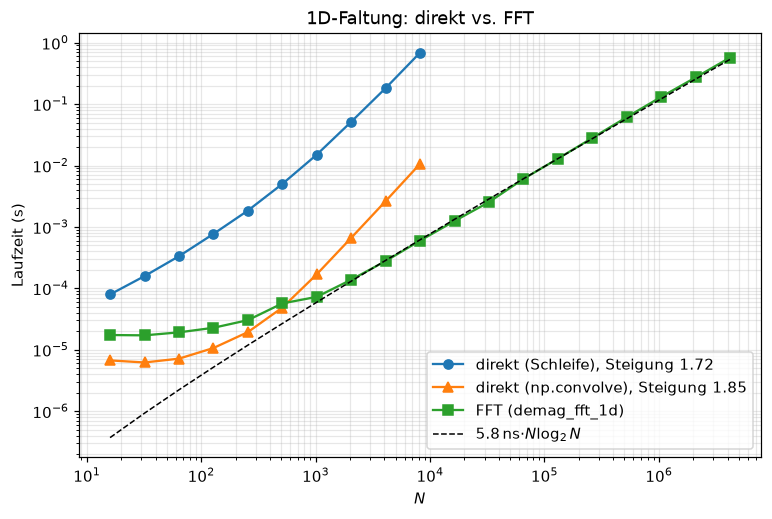

In [5]:
rng = np.random.default_rng(0)
sizes_direct = 2 ** np.arange(4, 14)
sizes_fft = 2 ** np.arange(4, 23)
t_direct = [best_time(demag_direct_1d, rng.standard_normal(n), repeat=3) for n in sizes_direct]
t_conv = [best_time(lambda m: np.convolve(m, kernel_1d(np.arange(-len(m) + 1, len(m))), "valid"),
                    rng.standard_normal(n), repeat=3) for n in sizes_direct]
t_fft = [best_time(demag_fft_1d, rng.standard_normal(n)) for n in sizes_fft]

big = sizes_direct >= 256
p_direct = np.polyfit(np.log(sizes_direct[big]), np.log(np.array(t_direct)[big]), 1)[0]
p_conv = np.polyfit(np.log(sizes_direct[big]), np.log(np.array(t_conv)[big]), 1)[0]
big_f = sizes_fft >= 2 ** 12
c_fft = np.median(np.array(t_fft)[big_f] / (sizes_fft[big_f] * np.log2(sizes_fft[big_f])))

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(sizes_direct, t_direct, "o-", label=f"direkt (Schleife), Steigung {p_direct:.2f}")
ax.loglog(sizes_direct, t_conv, "^-", label=f"direkt (np.convolve), Steigung {p_conv:.2f}")
ax.loglog(sizes_fft, t_fft, "s-", label="FFT (demag_fft_1d)")
ax.loglog(sizes_fft, c_fft * sizes_fft * np.log2(sizes_fft), "k--", lw=1, label=rf"${c_fft*1e9:.1f}\,$ns$\cdot N\log_2 N$")
ax.set(xlabel="$N$", ylabel="Laufzeit (s)", title="1D-Faltung: direkt vs. FFT")
ax.legend(); ax.grid(True, which="both", alpha=0.3); plt.show()

print(f"Steigung direkt (Schleife) {p_direct:.2f}, np.convolve {p_conv:.2f}; FFT: {c_fft*1e9:.2f} ns * N log2 N")
for n, td, tf in zip(sizes_direct, t_direct, t_fft):
    print(f"N = {n:5d}: direkt {td*1e3:9.3f} ms, FFT {tf*1e3:7.3f} ms, Faktor {td/tf:8.1f}")

#### Beobachtungen

- **Direkt:** gefittete Steigung 1.7 (Schleife) bzw. 1.85 (`np.convolve`). Bei kleinem $N$ dominiert der Python-Overhead pro Zeile;
  zwischen $N = 4096$ und $8192$ wächst die Zeit um Faktor 3.8, also lokal wie $N^{1.9}$. Asymptotisch $O(N^2)$.
- **FFT:** etwa $6\,\text{ns}\cdot N\log_2 N$, also $O(N\log N)$. Unter $N \approx 256$ ist sie fast konstant (Overhead des Aufrufs).
- Der Vorsprung wächst mit $N$: Faktor 18 bei $N = 64$, 650 bei $N = 4096$, 1150 bei $N = 8192$.

**Was passiert für $N \ne 2^m$?** Gemessen werden drei Arten von Längen um $2^{16}$:
Zweierpotenz, glatte Zahl (nur Faktoren 2, 3, 5) und Primzahl. `demag_fft_1d` paddet auf $L = 2N$, die Primzahl $N$
gibt also $L = 2p$.

In [6]:
from scipy.fft import next_fast_len


def prime_below(n):
    """Largest prime < n (small sieve-free search, n ~ 1e5)."""
    k = n - 1
    while any(k % q == 0 for q in range(2, int(k ** 0.5) + 1)):
        k -= 1
    return k


cases = {"2^16": 2 ** 16, "2^16 + 1": 2 ** 16 + 1, "3^4 * 5^4 = 50625": 50625,
         "Primzahl < 2^16": prime_below(2 ** 16), "Primzahl < 2^17": prime_below(2 ** 17)}
t_any = {}
for name, n in cases.items():
    m = rng.standard_normal(n)
    t_any[name] = best_time(demag_fft_1d, m)
    print(f"{name:>24}: N = {n:6d}, L = 2N = {2*n:6d}, FFT {t_any[name]*1e3:7.2f} ms, "
          f"pro N log2 N: {t_any[name]/(n*np.log2(n))*1e9:6.2f} ns")

                    2^16: N =  65536, L = 2N = 131072, FFT    6.30 ms, pro N log2 N:   6.01 ns
                2^16 + 1: N =  65537, L = 2N = 131074, FFT   29.07 ms, pro N log2 N:  27.72 ns
       3^4 * 5^4 = 50625: N =  50625, L = 2N = 101250, FFT    4.04 ms, pro N log2 N:   5.10 ns
         Primzahl < 2^16: N =  65521, L = 2N = 131042, FFT   30.17 ms, pro N log2 N:  28.78 ns
         Primzahl < 2^17: N = 131071, L = 2N = 262142, FFT   66.48 ms, pro N log2 N:  29.83 ns


#### Beobachtungen

- **Glatte Länge** ($50625 = 3^4 5^4$, $L = 2\cdot 3^4 5^4$): genauso schnell pro $N\log_2 N$ wie die Zweierpotenz (5.1 vs. 5.5 ns).
  pocketfft (hinter `np.fft`) zerlegt $L$ in beliebige kleine Primfaktoren (Mixed-Radix-Cooley-Tukey).
- **Großer Primfaktor:** $2^{16}+1 = 65537$ ist eine Primzahl, ebenso 65521. Dann ist $L = 2p$, und die FFT ist 5- bis 6-mal langsamer
  (29 ns pro $N\log_2 N$). Sie bleibt $O(N\log N)$: Für große Primfaktoren rechnet pocketfft mit Bluestein, das die DFT als Faltung
  auf einer glatten Länge $\ge 2p - 1$ schreibt. Das kostet mehrere FFTs statt einer.
- Eine Zweierpotenz ist also nicht nötig, aber die Länge sollte nur kleine Primfaktoren haben. Weil $m$ ohnehin gepaddet wird,
  darf man $L$ frei wählen: siehe 1e.

### 1e) Optimierung

`demag_fft_1d_fast` ändert drei Dinge gegenüber `demag_fft_1d`:

1. **Reelle FFT** (`rfft`/`irfft`): $m$ und $K$ sind reell, die Spektren hermitesch. Man braucht nur $L/2+1$ Werte, das spart etwa die Hälfte.
2. **Kernel-Spektrum cachen**: $\hat K$ hängt nur von $L$ ab, nicht von $m$. In einer Simulation ändert sich $m$ in jedem Zeitschritt,
   $K$ nie. Pro Aufruf bleiben 2 statt 3 FFTs.
3. **Glatte Padding-Länge**: statt $L = 2N$ die kleinste Länge $L \ge 2N - 1$ mit nur kleinen Primfaktoren (`next_fast_len`).

In [7]:
import functools
import demag


def fft_1d_rfft_only(m):
    """Step 1 only: rfft, L = 2N, kernel FFT recomputed every call."""
    n = len(m); L = 2 * n
    K_hat = np.fft.rfft(kernel_1d(np.fft.fftfreq(L, 1 / L)))
    return np.fft.irfft(K_hat * np.fft.rfft(m, L), L)[:n]


variants = {"demag_fft_1d (fft, 2N)": demag_fft_1d, "+ rfft": fft_1d_rfft_only,
            "+ rfft + Cache + next_fast_len": demag_fft_1d_fast}
bench = {"2^16": 2 ** 16, "2^20": 2 ** 20, "Primzahl < 2^16": prime_below(2 ** 16), "2^16 + 1": 2 ** 16 + 1}
res = {}
for vname, f in variants.items():
    for bname, n in bench.items():
        m = rng.standard_normal(n)
        f(m)  # warm-up (fills the cache)
        res[vname, bname] = best_time(f, m, repeat=7)
        assert np.allclose(f(m), demag_fft_1d(m), atol=1e-12)

print(f"{'Variante':>32}" + "".join(f"{b:>18}" for b in bench))
for vname in variants:
    print(f"{vname:>32}" + "".join(f"{res[vname, b]*1e3:15.2f} ms" for b in bench))
print(f"{'Beschleunigung gesamt':>32}" + "".join(
    f"{res['demag_fft_1d (fft, 2N)', b] / res['+ rfft + Cache + next_fast_len', b]:17.1f}x" for b in bench))
print("\nnext_fast_len(2N-1) für die Primzahl:", next_fast_len(2 * prime_below(2 ** 16) - 1, real=True),
      "statt", 2 * prime_below(2 ** 16))

                        Variante              2^16              2^20   Primzahl < 2^16          2^16 + 1
          demag_fft_1d (fft, 2N)           6.22 ms         135.52 ms          29.68 ms          28.88 ms
                          + rfft           3.40 ms          76.51 ms          29.90 ms          28.63 ms
  + rfft + Cache + next_fast_len           1.35 ms          37.10 ms           1.43 ms           1.33 ms
           Beschleunigung gesamt              4.6x              3.7x             20.8x             21.7x

next_fast_len(2N-1) für die Primzahl: 131072 statt 131042


#### Beobachtungen

- **rfft** spart bei Zweierpotenzen 40 % (5.7 → 3.4 ms bei $2^{16}$), bei $L = 2p$ fast nichts, weil dort Bluestein dominiert.
- **Cache + `next_fast_len`**: nochmals Faktor 2 bis 2.5 bei Zweierpotenzen (nur 2 statt 3 FFTs), bei Primzahl-$N$ Faktor 22,
  weil $L = 131072$ statt $2\cdot65521$.
- Gesamt: 3.4- bis 4.1-mal schneller bei $N = 2^k$, 22-mal bei ungünstigem $N$. Ergebnis identisch (geprüft mit `allclose`).

> **Frage:** Wie kann man den Algorithmus weiter optimieren?
>
> **Antwort:**
> - **Kernel einmal transformieren** und für alle Zeitschritte wiederverwenden (gemacht). Im Fourierraum ist $\hat K$ reell und gerade, weil $K$ gerade ist:
>   man könnte ihn als reelles Array halber Länge speichern.
> - **Glatte Längen** wählen (gemacht) und **reelle Transformationen** (gemacht).
> - **Mehrere Threads**: `scipy.fft.rfft(..., workers=-1)`; bringt erst bei großen Arrays etwas.
> - **FFTW** (`pyfftw`) mit einem vorab geplanten Transform; **GPU** (cupy) für große 3D-Gitter.
> - **Weniger Padding ausnutzen:** Die Hälfte des gepaddeten Arrays von $m$ ist null, die Hälfte des Ergebnisses wird weggeworfen.
>   Pruned FFTs sparen diese Arbeit; in 3D macht das bis zu Faktor 2 pro Achse aus.
> - **Genauigkeit statt Geschwindigkeit:** `float32` halbiert Speicher und Bandbreite, wenn $10^{-7}$ relativ reichen.

## 2 Erweiterung auf 3D

### 2a) Tensorkernel

Komponentenweise geschrieben ist das Dipolfeld linear in $\vec m$:

$$h_i(\vec r) = \sum_j K_{ij}(\vec r)\, m_j, \qquad K_{ij}(\vec r) = \frac{1}{4\pi r^3}\Big(3\frac{r_i r_j}{r^2} - \delta_{ij}\Big), \qquad K_{ij}(0) = -\tfrac13\delta_{ij}.$$

$K$ ist symmetrisch, $K_{ij} = K_{ji}$: **6 unabhängige Komponenten** ($xx, yy, zz, xy, xz, yz$), außerdem spurfrei für $r\ne0$.
Auf einem $n\times n\times n$-Gitter wird jede Komponente auf $(2n)^3$ gepaddet, in jeder Achse in Wraparound-Anordnung.

**FFTs:** 6 Kernel-FFTs, einmal vorab (sie hängen nur vom Gitter ab). Pro Feldauswertung 3 Vorwärts-FFTs ($m_x, m_y, m_z$),
die Multiplikation $\hat h_i = \sum_j \hat K_{ij}\hat m_j$ im Fourierraum (9 Produkte, punktweise) und 3 Rück-FFTs.
Also **6 FFTs pro Auswertung**, alle reell (`rfftn`) und auf $(2n)^3$.

### 2b) Validierung

Drei unabhängige Prüfungen:

1. **Gegen die direkte Summe** auf kleinen Gittern (zufälliges $m$). Die FFT ist nur eine schnellere Art, dieselbe Summe zu rechnen,
   der Unterschied muss Rundung sein.
2. **Einzelner Dipol**: das FFT-Feld muss an jeder Zelle gleich `dipole_field` sein (Test `test_direct_3d_single_dipole`).
3. **Analytische Lösung der Kugel**: homogen magnetisierte Kugel, im Inneren $\vec h = -\vec m/3$ exakt. Das prüft die Physik,
   nicht nur die Arithmetik.

In [8]:
eps = np.finfo(float).eps
print(" n   Zellen  max|h_fft - h_direkt|   / eps    t_direkt     t_fft")
errs_3d = []
for n in [2, 4, 6, 8, 10, 12, 14]:
    m = np.random.default_rng(n).standard_normal((3, n, n, n))
    t0 = time.perf_counter(); h_d = demag_direct_3d(m); td = time.perf_counter() - t0
    t0 = time.perf_counter(); h_f = demag_fft_3d(m); tf = time.perf_counter() - t0
    err = np.max(np.abs(h_f - h_d)) / np.max(np.abs(h_d))
    errs_3d.append(err)
    print(f"{n:2d} {n**3:8d}   {err:12.2e}   {err/eps:12.1f}  {td*1e3:8.1f} ms {tf*1e3:7.2f} ms")

 n   Zellen  max|h_fft - h_direkt|   / eps    t_direkt     t_fft
 2        8       1.08e-16            0.5       0.2 ms    0.23 ms
 4       64       4.00e-16            1.8       1.0 ms    0.25 ms
 6      216       6.37e-16            2.9       5.3 ms    0.41 ms
 8      512       9.26e-16            4.2      22.0 ms    0.99 ms
10     1000       1.51e-15            6.8      72.3 ms    1.11 ms
12     1728       2.24e-15           10.1     204.9 ms    1.77 ms
14     2744       2.87e-15           12.9     497.6 ms    2.96 ms


 R    Zellen  <h_z> innen   max|h_z + 1/3|   rel. Volumenfehler   Fehler im Kern (r < R/2)
 2       32   -0.33333     0.1161        -0.0451            0.0000
 4      280   -0.33333     0.1522        +0.0445            0.0048
 6      912   -0.33333     0.2190        +0.0080            0.0018
 8     2176   -0.33333     0.2224        +0.0146            0.0010
12     7208   -0.33333     0.2431        -0.0042            0.0014
16    17256   -0.33333     0.2598        +0.0058            0.0012
24    57856   -0.33333     0.2847        -0.0009            0.0007


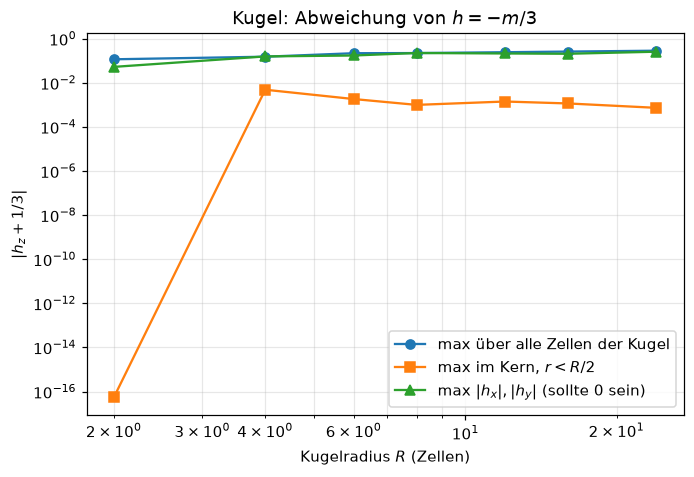

In [9]:
def ball(n, radius):
    """Mask of a ball with given radius (in cells) centred in an n^3 grid."""
    x = np.arange(n) - (n - 1) / 2
    X, Y, Z = np.meshgrid(x, x, x, indexing="ij")
    return X**2 + Y**2 + Z**2 <= radius**2


def cube(n, a):
    """Mask of a cube with edge a (cells) centred in an n^3 grid."""
    x = np.abs(np.arange(n) - (n - 1) / 2)
    X, Y, Z = np.meshgrid(x, x, x, indexing="ij")
    return (X < a / 2) & (Y < a / 2) & (Z < a / 2)


def uniform(mask, direction=(0, 0, 1)):
    """Uniform unit magnetization along direction inside mask."""
    return np.array(direction, float)[:, None, None, None] * mask


print(" R    Zellen  <h_z> innen   max|h_z + 1/3|   rel. Volumenfehler   Fehler im Kern (r < R/2)")
radii = [2, 4, 6, 8, 12, 16, 24]
sphere_err = []
for R in radii:
    n = 2 * R + 4
    mask = ball(n, R)
    h = demag_fft_3d(uniform(mask))
    inner = ball(n, R / 2)
    vol_err = mask.sum() / (4 / 3 * np.pi * R**3) - 1
    sphere_err.append((np.max(np.abs(h[2][mask] + 1 / 3)), np.max(np.abs(h[2][inner] + 1 / 3)), np.max(np.abs(h[:2][:, mask]))))
    print(f"{R:2d} {mask.sum():8d}   {h[2][mask].mean():+.5f}     {sphere_err[-1][0]:.4f}        {vol_err:+.4f}"
          f"            {sphere_err[-1][1]:.4f}")

sphere_err = np.array(sphere_err)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(radii, sphere_err[:, 0], "o-", label=r"max über alle Zellen der Kugel")
ax.loglog(radii, sphere_err[:, 1], "s-", label=r"max im Kern, $r < R/2$")
ax.loglog(radii, sphere_err[:, 2], "^-", label=r"max $|h_x|, |h_y|$ (sollte 0 sein)")
ax.set(xlabel="Kugelradius $R$ (Zellen)", ylabel=r"$|h_z + 1/3|$", title="Kugel: Abweichung von $h = -m/3$")
ax.legend(); ax.grid(True, which="both", alpha=0.3); plt.show()

#### Beobachtungen (FFT vs. direkte Summe, Kugel)

- **FFT gegen direkte Summe:** Abweichung $10^{-16}$ bis $3\cdot10^{-15}$, also 0.5 bis 13 $\varepsilon$. Sie wächst langsam mit der Gittergröße,
  weil mehr Terme aufsummiert werden und eine größere FFT mehr Rundungsschritte hat (etwa $\varepsilon\log N$ für die FFT,
  eher $\varepsilon\sqrt N$ für die Summe). Die FFT ist also kein Näherungsverfahren.
- Laufzeit: bei $n = 14$ (2744 Zellen) direkt 0.5 s, FFT 2.7 ms.
- **Kugel:** Der Mittelwert über alle Zellen ist exakt $-1/3$ (auf allen Stellen). Das ist kein Zufall: Die gerasterte Kugel hat kubische
  Symmetrie, also ist $\sum_{i\ne j} K_{xx} = \sum K_{yy} = \sum K_{zz}$, und weil $K$ spurfrei ist, ist jede Summe null. Übrig bleibt der Selbstterm.
- Im Kern ($r < R/2$) liegt $h_z$ bis auf $10^{-3}$ bei $-1/3$, mit wachsendem $R$ wird es besser ($5\cdot10^{-3}$ bei $R = 4$, $7\cdot10^{-4}$ bei $R = 24$).
- In den Zellen direkt an der Oberfläche weicht $h_z$ bis zu 0.26 ab, und das wird mit wachsendem $R$ **nicht** besser: Die Treppenstufen-Oberfläche
  bleibt aus Sicht einer Randzelle immer gleich rau (Ecken im Abstand einer Zelle). Der Fehler wird nur auf weniger Zellen beschränkt.
- $h_x, h_y$ sind an den Stufen nicht null (bis 0.26), im Kern unter $10^{-3}$.

In [10]:
# far field: a small sphere looks like a point dipole with moment = number of cells
n = 48
mask = ball(n, 3)
h = demag_fft_3d(uniform(mask))
c = (n - 1) / 2
for dz in [6, 10, 15, 20]:
    i = int(c + 0.5) + dz - 1  # cell on the z-axis above the centre
    rz = i - c
    h_point = dipole_field(np.array([0, 0, mask.sum()]), np.array([0, 0, rz]))[2]
    print(f"Abstand {rz:5.1f}: h_z = {h[2, n//2, n//2, i]:.4e}, Punktdipol mit m = {mask.sum()}: {h_point:.4e}, "
          f"rel. {h[2, n//2, n//2, i]/h_point - 1:+.1e}")

Abstand   5.5: h_z = 1.2285e-01, Punktdipol mit m = 136: 1.3010e-01, rel. -5.6e-02
Abstand   9.5: h_z = 2.4835e-02, Punktdipol mit m = 136: 2.5246e-02, rel. -1.6e-02
Abstand  14.5: h_z = 7.0502e-03, Punktdipol mit m = 136: 7.0999e-03, rel. -7.0e-03
Abstand  19.5: h_z = 2.9078e-03, Punktdipol mit m = 136: 2.9191e-03, rel. -3.9e-03


#### Beobachtungen (Fernfeld)

Eine kleine Kugel ($R = 3$, 136 Zellen) sieht von weitem aus wie ein Punktdipol mit $m = 136$. Die Abweichung fällt von 6 % bei Abstand 5.5 auf 0.4 % bei 19.5.

> **Frage:** Wie prüft man auf Korrektheit, wie groß ist der Fehler, und wovon hängt er ab?
>
> **Antwort:** Zwei Arten von Fehler muss man trennen.
> - **Arithmetik** (rechnet die FFT die richtige Summe?): Vergleich mit der direkten Summe auf kleinen Gittern und mit dem Einzeldipol.
>   Fehler $10^{-16}\dots10^{-15}$, wächst nur langsam mit der Gittergröße. Hängt nur von der Gleitkommagenauigkeit ab.
> - **Diskretisierung** (ist die Summe die richtige Physik?): Vergleich mit analytischen Lösungen: Kugel innen $-\vec m/3$, Fernfeld $\to$ Punktdipol.
>   Der Fehler hängt von der **Auflösung** (Zellen pro Radius), vom **Ort** (Abstand zur Oberfläche) und von der **Geometrie** ab (Treppenstufen
>   bei gekrümmten Oberflächen). Im Inneren $10^{-3}$, an gestuften Oberflächen bis $0.26$, im Fernfeld $\propto (a/r)^2$ relativ.
>   Dazu kommt die Punktdipol-Näherung selbst, die zwischen direkten Nachbarn am größten ist.

### 2c) Homogen magnetisierter Würfel und Kugel

$\vec m = \hat z$, Kugel mit Radius $R = 16$, Würfel mit Kante $a = 32$, Gitter $n = 48$. Gezeigt ist der Schnitt $y = $ Mitte.

  Kugel, R = 16: <h_z> innen = -0.3333, Streuung (std) = 0.0325, min = -0.5198, max = -0.0736, Zentrum = -0.3333
 Würfel, a = 32: <h_z> innen = -0.3333, Streuung (std) = 0.0991, min = -0.5777, max = -0.1299, Zentrum = -0.3333


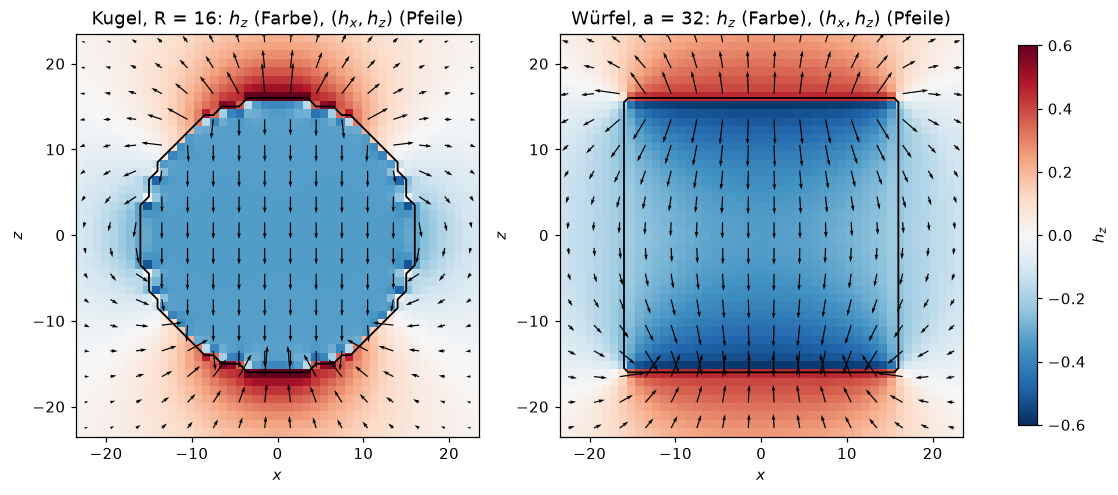

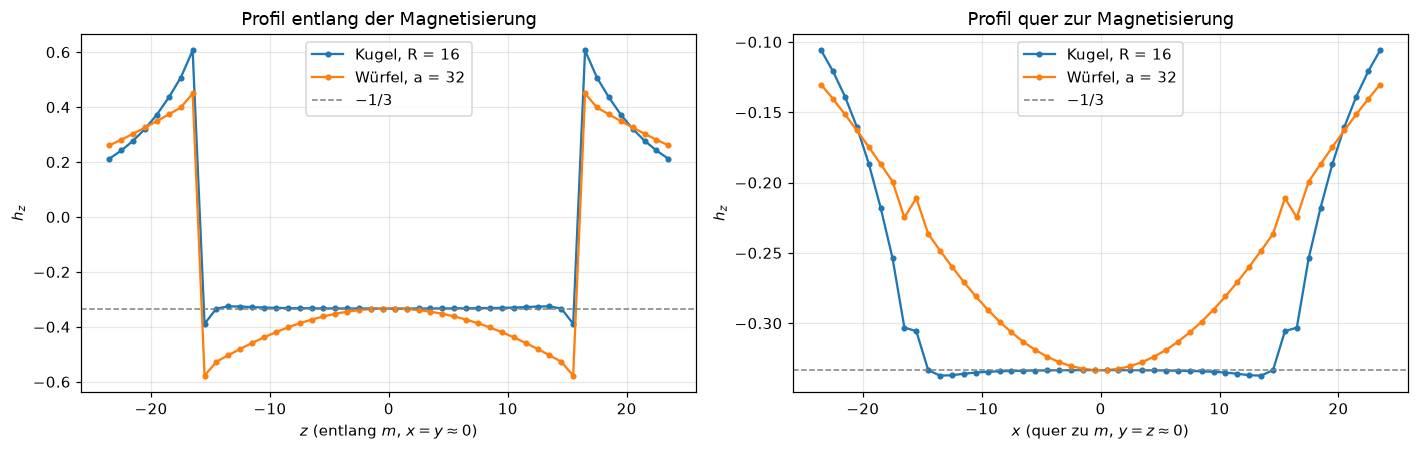

In [11]:
n = 48
bodies = {"Kugel, R = 16": ball(n, 16), "Würfel, a = 32": cube(n, 32)}
fields = {name: demag_fft_3d(uniform(mask)) for name, mask in bodies.items()}
j = n // 2  # slice y = centre (grid has an even size, slice just off centre)
x = np.arange(n) - (n - 1) / 2

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, (name, h) in zip(axes, fields.items()):
    mask = bodies[name]
    im = ax.imshow(h[2, :, j, :].T, origin="lower", extent=[x[0], x[-1], x[0], x[-1]], cmap="RdBu_r", vmin=-0.6, vmax=0.6)
    s = slice(1, None, 3)
    ax.quiver(x[s], x[s], h[0, s, j, s].T, h[2, s, j, s].T, scale=8, width=0.003)
    ax.contour(x, x, mask[:, j, :].T, levels=[0.5], colors="k", linewidths=1.2)
    ax.set(xlabel="$x$", ylabel="$z$", title=f"{name}: $h_z$ (Farbe), $(h_x, h_z)$ (Pfeile)", aspect="equal")
fig.colorbar(im, ax=axes, shrink=0.8, label="$h_z$")
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for name, h in fields.items():
    ax1.plot(x, h[2, n // 2, j, :], ".-", label=name)
    ax2.plot(x, h[2, :, j, n // 2], ".-", label=name)
for ax, lab in ((ax1, "$z$ (entlang $m$, $x = y \\approx 0$)"), (ax2, "$x$ (quer zu $m$, $y = z \\approx 0$)")):
    ax.axhline(-1 / 3, color="gray", ls="--", lw=1, label="$-1/3$")
    ax.set(xlabel=lab, ylabel="$h_z$"); ax.legend(); ax.grid(True, alpha=0.3)
ax1.set_title("Profil entlang der Magnetisierung"); ax2.set_title("Profil quer zur Magnetisierung")
plt.tight_layout(); plt.show()

for name, h in fields.items():
    mask = bodies[name]
    hz = h[2][mask]
    print(f"{name:>15}: <h_z> innen = {hz.mean():+.4f}, Streuung (std) = {hz.std():.4f}, "
          f"min = {hz.min():+.4f}, max = {hz.max():+.4f}, Zentrum = {h[2, n//2, n//2, n//2]:+.4f}")

#### Beobachtungen

- **Kugel:** innen gleichmäßig. Mittelwert $-0.3333$, Streuung nur 0.03, und die stammt fast ganz aus den Randzellen (Profil oben: flach bei $-1/3$).
  Direkt außerhalb an den Polen $h_z = 0.61$; analytisch $\tfrac23 (R/r)^3 = 0.608$ bei $r = 16.5$.
- **Würfel:** innen **nicht** gleichmäßig. Im Zentrum genau $-1/3$ (kubische Symmetrie), an den Polflächen $-0.58$, in der Mitte der Seitenflächen nur $-0.21$,
  an den Kantenmitten $-0.13$. Streuung 0.10, dreimal so groß wie bei der Kugel.
- Der Mittelwert über das Volumen ist bei beiden $-1/3$: Der Entmagnetisierungsfaktor des Würfels ist $1/3$, nur nicht lokal.

> **Frage:** Warum ist das Feld in der Kugel gleichmäßig, im Würfel nicht?
>
> **Antwort:** Bei homogener Magnetisierung gibt es nur Oberflächenladungen $\sigma = \vec m\cdot\hat n$.
> Eine Kugel mit $\sigma = m\cos\theta$ ist dasselbe wie zwei gleichmäßig geladene Kugeln ($\pm\rho$), um ein kleines $\vec\delta$ gegeneinander verschoben.
> Im Inneren einer homogen geladenen Kugel ist das Feld linear in $\vec r$ ($\vec E = \rho\vec r/3$). Die Differenz zweier solcher Felder ist konstant:
> $\vec h = -\rho\vec\delta/3 = -\vec m/3$. Das gilt für jedes Ellipsoid (dort ist das Feld innen ebenfalls linear), aber nur für Ellipsoide.
> Beim Würfel sitzen die Ladungen auf zwei ebenen, endlichen Platten. Ihr Feld ist nahe der Plattenmitte am stärksten und fällt zu den Kanten hin ab,
> wie bei einem Plattenkondensator mit Randfeld. Daher $-0.58$ an den Polflächen und schwächeres Feld an den Seiten. In den Ecken ist es am ungleichmäßigsten.

### 2d) Formulierung über magnetische Ladungen

$\rho = -\nabla\cdot\vec m$, $\ \phi = K_c * \rho$ mit $K_c(r) = 1/(4\pi r)$, $\ \vec h = -\nabla\phi$.
Divergenz und Gradient als zentrale Differenzen (`np.gradient`), $\phi$ als gepaddete FFT-Faltung.
Für $K_c(0)$ nehme ich das Potential im Mittelpunkt eines Einheitswürfels mit Ladungsdichte 1,
$\frac{1}{4\pi}\int_{\text{Würfel}} \frac{dV}{r} = \frac{3\ln(2+\sqrt3) - \pi/2}{4\pi} \approx 0.1894$.

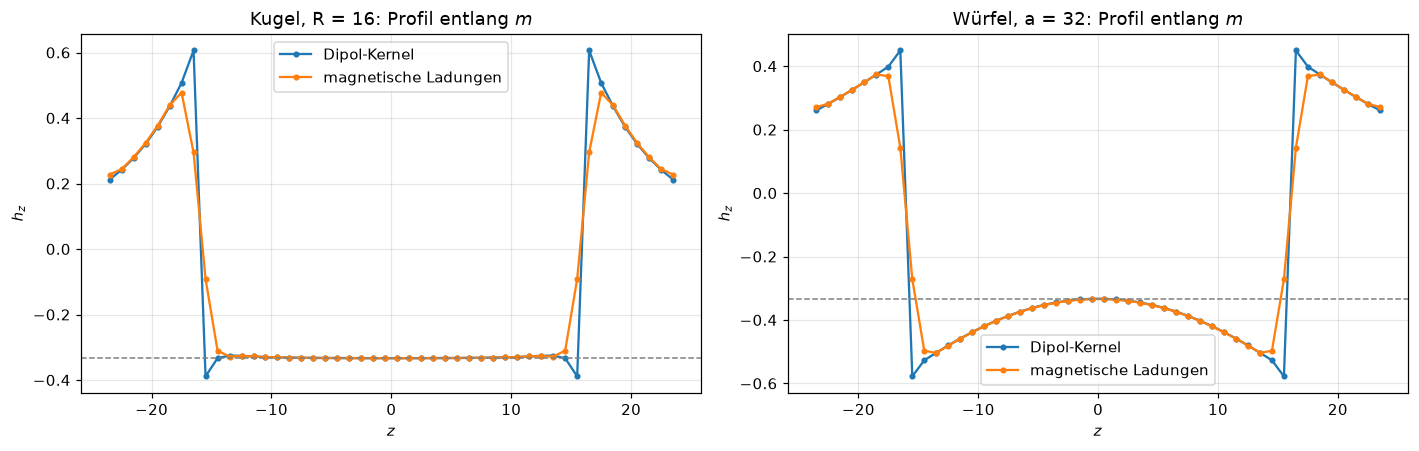

In [12]:
fields_c = {name: charge_field_3d(uniform(mask)) for name, mask in bodies.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (name, h) in zip(axes, fields.items()):
    ax.plot(x, h[2, n // 2, j, :], ".-", label="Dipol-Kernel")
    ax.plot(x, fields_c[name][2, n // 2, j, :], ".-", label="magnetische Ladungen")
    ax.axhline(-1 / 3, color="gray", ls="--", lw=1)
    ax.set(xlabel="$z$", ylabel="$h_z$", title=f"{name}: Profil entlang $m$"); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [13]:
def shell_errors(h_a, h_b, mask):
    """Max |h_a - h_b| on the surface layer, deep inside and outside of the body."""
    from scipy.ndimage import binary_erosion, binary_dilation
    inner = binary_erosion(mask, iterations=3)
    outer = ~binary_dilation(mask, iterations=3)
    surface = ~inner & ~outer
    d = np.linalg.norm(h_a - h_b, axis=0)
    return d[surface].max(), d[inner].max(), d[outer].max()


print(f"{'':>15}  max|h_dip - h_chg| an der Oberfläche (±3 Zellen)   tief innen   außen")
for name, mask in bodies.items():
    s, i_, o = shell_errors(fields[name], fields_c[name], mask)
    print(f"{name:>15}:  {s:30.4f}   {i_:20.4f}  {o:10.4f}")

print("\nKugel R = 8 ... 24, Abweichung von -1/3 im Kern (r < R/2):")
for R in [8, 12, 16, 24]:
    nn = 2 * R + 4
    mask = ball(nn, R); inner = ball(nn, R / 2)
    hd, hc = demag_fft_3d(uniform(mask)), charge_field_3d(uniform(mask))
    print(f"  R = {R:2d}: Dipol {np.max(np.abs(hd[2][inner] + 1/3)):.4f}, Ladungen {np.max(np.abs(hc[2][inner] + 1/3)):.4f}")

m_big = uniform(ball(64, 24))
t_dip = best_time(demag_fft_3d, m_big, repeat=3)
t_chg = best_time(charge_field_3d, m_big, repeat=3)
print(f"\nLaufzeit n = 64: Dipol-Kernel {t_dip:.2f} s, Ladungen {t_chg:.2f} s, Verhältnis {t_dip/t_chg:.1f}")

                 max|h_dip - h_chg| an der Oberfläche (±3 Zellen)   tief innen   außen
  Kugel, R = 16:                          0.3122                 0.0030      0.0153
 Würfel, a = 32:                          0.3064                 0.0039      0.0112

Kugel R = 8 ... 24, Abweichung von -1/3 im Kern (r < R/2):
  R =  8: Dipol 0.0010, Ladungen 0.0016
  R = 12: Dipol 0.0014, Ladungen 0.0015
  R = 16: Dipol 0.0012, Ladungen 0.0012
  R = 24: Dipol 0.0007, Ladungen 0.0007

Laufzeit n = 64: Dipol-Kernel 0.25 s, Ladungen 0.05 s, Verhältnis 5.3


#### Beobachtungen

- **Tief innen** stimmen beide auf $3$–$4\cdot10^{-3}$ überein, **außerhalb** (mehr als 3 Zellen weg) auf $0.015$. Im Kern der Kugel erreichen beide $-1/3$
  bis auf $10^{-3}$ und werden mit wachsendem $R$ gleich gut.
- **An der Oberfläche** (±3 Zellen) bis $0.31$ Unterschied. Die zentrale Differenz verteilt die Flächenladung auf die beiden Nachbarzellen der Oberfläche,
  und der Gradient von $\phi$ verschmiert den Sprung nochmals. Im Profil: Die Ladungsformulierung geht über zwei Zellen von $-1/3$ auf $+0.48$,
  der Dipol-Kernel springt in einer Zelle von $-0.39$ auf $+0.61$. Analytisch springt die Kugel an den Polen von $-1/3$ auf $+2/3$,
  der Dipol-Kernel ist an der Oberfläche also genauer.
- Für glattes $\vec m$ (Gauß, Test `test_charge_field_converges_to_dipole_field_for_smooth_m`) unterscheiden sich beide um 7.1 % bei $\sigma = 3$ Zellen und
  1.9 % bei $\sigma = 6$: Faktor 3.7 bei doppelter Breite, also der Fehler 2. Ordnung der zentralen Differenzen, $\propto 1/\sigma^2$.
- **Aufwand:** Ladungen brauchen 1 Kernel-FFT und **2 FFTs pro Auswertung** ($\rho$ hin, $\phi$ zurück), der Dipol-Kernel 6 Kernel-FFTs und **6 pro Auswertung**
  plus 9 Produkte im Fourierraum. Gemessen bei $n = 64$: 0.05 s gegen 0.26 s, Faktor 5. Dafür kommen zwei Finite-Differenzen-Schritte dazu (billig, $O(N)$).

> **Frage:** Warum sind beide Formulierungen äquivalent?
>
> **Antwort:** Mit $\rho = -\nabla\cdot\vec m$ und partieller Integration (die Ableitung wandert von $\vec m$ auf den Kernel):
> $$\phi = -K_c * (\nabla\cdot\vec m) = -\nabla\cdot(K_c * \vec m), \qquad \vec h = -\nabla\phi = \nabla\nabla\cdot(K_c * \vec m) = (\nabla\nabla^T K_c) * \vec m .$$
> Der Dipol-Kernel ist also die zweite Ableitung des Coulomb-Kernels. Als Distribution gilt
> $$\partial_i\partial_j \frac{1}{4\pi r} = \frac{3\hat r_i\hat r_j - \delta_{ij}}{4\pi r^3} - \frac{\delta_{ij}}{3}\,\delta(\vec r),$$
> und der Delta-Term ist genau der Selbstterm $K(0) = -\tfrac13 I$ aus 1a. Im Kontinuum sind beide Formulierungen identisch;
> sie unterscheiden sich nur darin, wo diskretisiert wird: Beim Dipol-Kernel werden die Ableitungen exakt auf den Kernel angewandt,
> bei den Ladungen als finite Differenzen auf $\vec m$ und $\phi$.